## Sampling Distribution and CLT

### 1. Introduction

In statistics, we often use a sample to estimate a population characteristic, such as the population mean or population proportion.

However, different random samples from the same population can produce different estimates.

For example, one sample of 50 students may have an average math score of 68, while another sample of 50 students may have an average of 71.

This raises an important question:

**How does a sample statistic behave when we repeatedly take samples from the same population?**

To answer this, we study sampling distributions, standard error, and the Central Limit Theorem (CLT).

#### Load Libraries and dataset

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\Cloud Nine\Documents\Shalini\stats and probability\StudentsPerformance.csv")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### 2. Dataset Preparation

We will use the `math score` column to study sample means and the `gender` column to study sample proportions.

In this notebook, the complete dataset will serve as our reference population for simulation exercises.

In real-world research, we usually do not have access to the entire population, so its true parameters may be unknown.

In [17]:
math_scores = df["math score"].dropna()

population_size = len(math_scores)
population_mean = math_scores.mean()
population_std = math_scores.std(ddof=0)

print("Population size:", population_size)
print("Population mean:", population_mean)
print("Population standard deviation:", population_std)

Population size: 1000
Population mean: 66.089
Population standard deviation: 15.155496659628165


### 3. Population Distribution vs. Sample Distribution vs. Sampling Distribution

These three distributions describe different things.

#### 1. Population Distribution

The population distribution describes the values of an individual variable across the entire population.

Example: The distribution of math scores for all students in the dataset.

#### 2. Sample Distribution

A sample distribution describes the individual observations in one particular sample.

Example: The distribution of math scores for 50 randomly selected students.

#### 3. Sampling Distribution

A sampling distribution describes the values of a statistic calculated from many repeated samples of the same size.

Example:
1. Randomly select 50 students.
2. Calculate their average math score.
3. Repeat this process 1,000 times.
4. Plot the 1,000 sample means.

The resulting distribution of sample means is an approximation of the sampling distribution of the sample mean.

#### Remember

- Population distribution → Individual values in the population.
- Sample distribution → Individual values in one sample.
- Sampling distribution → A statistic calculated across repeated samples.

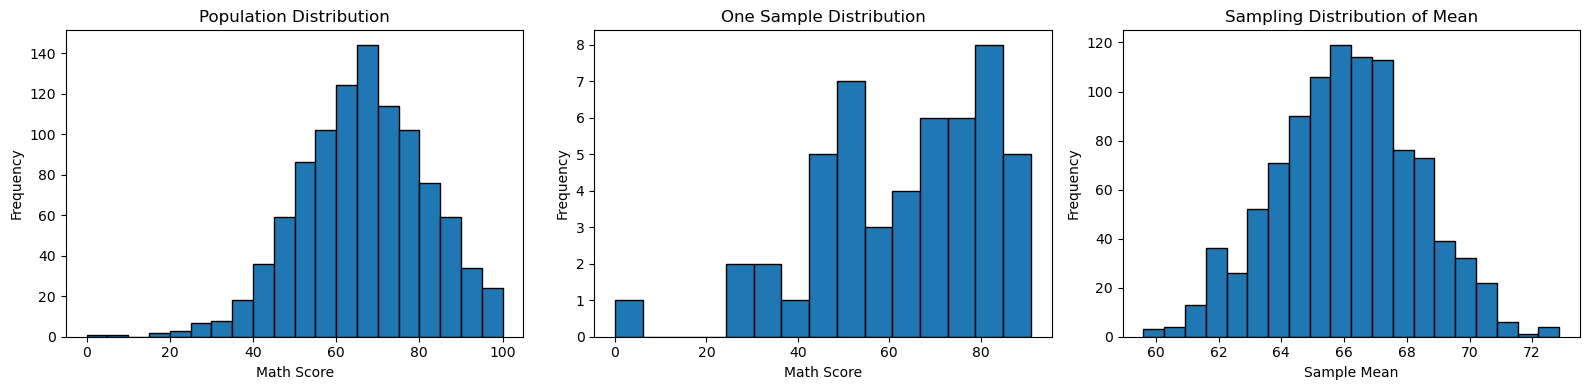

In [18]:
sample_size = min(50, population_size)

one_sample = math_scores.sample(
    n=sample_size,
    random_state=42
)

sample_means = []

for seed in range(1000):
    sample = math_scores.sample(
        n=sample_size,
        replace=True,
        random_state=seed
    )
    sample_means.append(sample.mean())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(math_scores, bins=20, edgecolor="black")
axes[0].set_title("Population Distribution")
axes[0].set_xlabel("Math Score")
axes[0].set_ylabel("Frequency")

axes[1].hist(one_sample, bins=15, edgecolor="black")
axes[1].set_title("One Sample Distribution")
axes[1].set_xlabel("Math Score")
axes[1].set_ylabel("Frequency")

axes[2].hist(sample_means, bins=20, edgecolor="black")
axes[2].set_title("Sampling Distribution of Mean")
axes[2].set_xlabel("Sample Mean")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

The first histogram shows individual math scores in the reference population. The second shows individual scores from one sample. The third shows the means from repeated samples.

The sampling distribution generally has less spread than the distribution of individual scores because each sample mean combines multiple observations.

Notice that the third histogram represents sample means, not individual student scores.

### 4. Sampling Distribution of the Sample Mean

The sampling distribution of the sample mean is the probability distribution of the means obtained from all possible samples of a fixed size, drawn according to a specified sampling design.

For a sample of size \(n\):
$$
\bar{X} = \frac{X_1 + X_2 + \cdots + X_n}{n}
$$

Under random sampling with independent observations from the same population, the expected value of the sample mean is:

$$
E(\bar{X}) = \mu
$$

**Where:**

- $\bar{X}$ = Sample mean
- $\mu$ = Population mean
- $n$ = Sample size

#### Intuition

Individual samples may have means that are too high or too low. Across repeated random samples, the sample means tend to centre around the population mean under the stated assumptions.

The sampling distribution helps us understand how reliable a sample mean is as an estimate of the population mean.


In [19]:
sample_size = min(50, population_size)
number_of_samples = 1000

sample_means = []

for seed in range(number_of_samples):
    sample = math_scores.sample(
        n=sample_size,
        replace=True,
        random_state=seed
    )
    sample_means.append(sample.mean())

sampling_distribution = pd.Series(sample_means)

print("Population mean:", population_mean)
print("Mean of sample means:", sampling_distribution.mean())
print("Number of sample means:", len(sampling_distribution))

Population mean: 66.089
Mean of sample means: 66.10286
Number of sample means: 1000


Compare the population mean with the mean of the repeated sample means.

They should generally be close when the samples are generated using the same random sampling process. Small differences may occur because we simulate a finite number of samples.

Here, sampling is performed with replacement to make the repeated samples independent of one another.

### 5. Standard Error of the Mean

Standard error (SE) measures the variability of a statistic across repeated samples.

For the sample mean, when observations are independent and identically distributed with finite variance:

$$
SE(\bar{X}) = \frac{\sigma}{\sqrt{n}}
$$

**Where:**

- $\sigma$ = Population standard deviation
- $n$ = Sample size

When the population standard deviation is unknown, we commonly estimate the standard error using the sample standard deviation:

$$
SE(\bar{X}) \approx \frac{s}{\sqrt{n}}
$$

Here, $s$ is the sample standard deviation.

#### Standard Deviation vs. Standard Error

- Standard deviation describes the spread of individual observations.
- Standard error describes the uncertainty or spread of a sample statistic across repeated samples.

#### Intuition

If students' individual scores vary widely, sample means will generally vary more. If the sample size increases, averaging more observations usually makes the sample mean more stable.


In [20]:
n = min(50, population_size)

sample = math_scores.sample(
    n=n,
    random_state=42
)

sample_std = sample.std(ddof=1)
estimated_se = sample_std / np.sqrt(n)

theoretical_se = population_std / np.sqrt(n)

print("Sample standard deviation:", sample_std)
print("Estimated standard error:", estimated_se)
print("Reference SE using population SD:", theoretical_se)


Sample standard deviation: 19.126261462999516
Estimated standard error: 2.7048618358467786
Reference SE using population SD: 2.143310892054629


The sample standard deviation measures the spread of the sampled students' scores. The estimated standard error measures the uncertainty in the sample mean.

The two standard errors shown use different information: one uses the sample standard deviation, while the other uses the known standard deviation of our reference population.

Because this is a simulation exercise, we can calculate both. In practical analysis, the population standard deviation is usually unknown.


### 6. Effect of Sample Size on Standard Error

The standard error of the sample mean is:

$$
SE(\bar{X}) = \frac{\sigma}{\sqrt{n}}
$$

This formula shows that the standard error decreases as the sample size increases.

For example, keeping the population standard deviation constant:

- If the sample size increases from 25 to 100, it increases fourfold.
- The standard error becomes half as large.

#### Important Insight

To reduce the standard error by half, you generally need four times the sample size, not twice the sample size.

This relationship assumes independent observations under an appropriate sampling design. Sampling without replacement from a finite population may require a finite population correction.


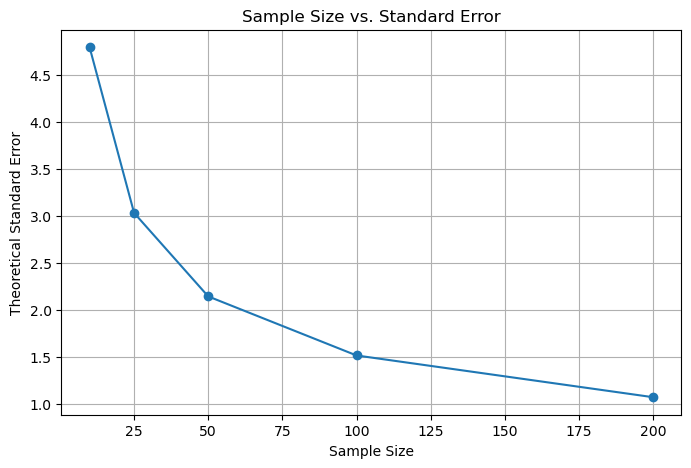

In [21]:
sample_sizes = [
    n for n in [10, 25, 50, 100, 200]
    if n <= population_size
]

se_results = []

for n in sample_sizes:
    theoretical_se = population_std / np.sqrt(n)

    se_results.append({
        "Sample Size": n,
        "Theoretical Standard Error": theoretical_se
    })

se_df = pd.DataFrame(se_results)
se_df

plt.figure(figsize=(8, 5))

plt.plot(
    se_df["Sample Size"],
    se_df["Theoretical Standard Error"],
    marker="o"
)

plt.title("Sample Size vs. Standard Error")
plt.xlabel("Sample Size")
plt.ylabel("Theoretical Standard Error")
plt.grid(True)
plt.show()


The graph should show a downward trend: increasing sample size reduces the theoretical standard error.

The reduction is not linear. Doubling the sample size does not halve the standard error; it reduces it by a factor of \(1/\sqrt{2}\), assuming the other conditions remain unchanged.

### 7. Central Limit Theorem (CLT)

The Central Limit Theorem states that, under suitable conditions, the sampling distribution of the sample mean becomes approximately normal as the sample size increases, even when the original population distribution is not normal.

For independent, identically distributed observations with finite mean \(\mu\) and finite variance \(\sigma^2\):

\[
\bar{X}\approx N\left(\mu,\frac{\sigma^2}{n}\right)
\]

For the standardised sample mean:

\[
Z=\frac{\bar{X}-\mu}{\sigma/\sqrt{n}}
\]

The distribution of this standardised statistic approaches the standard normal distribution as the sample size grows under the CLT's assumptions.

#### Intuition

Imagine a population whose individual observations are strongly right-skewed.

If we repeatedly select sufficiently large random samples and calculate each sample's mean, the distribution of those means often becomes more bell-shaped.

#### Important Points

- The original population does not have to be normally distributed.
- The sample means tend to centre around the population mean.
- Their standard deviation is the standard error.
- The sample size needed for a good approximation depends on the population distribution and other conditions.
- The CLT does not say that the original data itself becomes normally distributed.


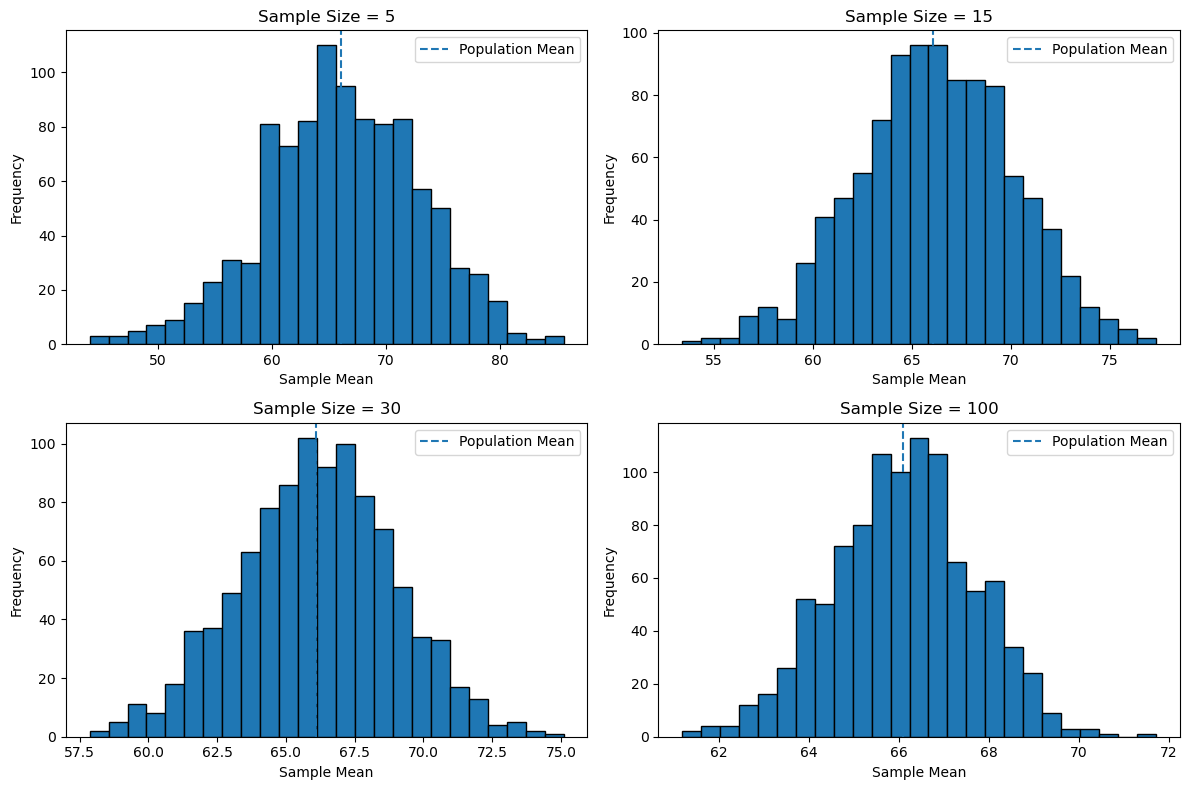

In [22]:
sample_sizes = [5, 15, 30, 100]
number_of_samples = 1000

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, n in zip(axes.flat, sample_sizes):
    sample_means = []

    for seed in range(number_of_samples):
        sample = math_scores.sample(
            n=n,
            replace=True,
            random_state=seed
        )
        sample_means.append(sample.mean())

    ax.hist(
        sample_means,
        bins=25,
        edgecolor="black"
    )

    ax.axvline(
        population_mean,
        linestyle="--",
        label="Population Mean"
    )

    ax.set_title(f"Sample Size = {n}")
    ax.set_xlabel("Sample Mean")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

The four histograms show the sampling distributions of the sample mean for different sample sizes.

- When the sample size is small, the sample means may show more variability and may not look very normal.
- As the sample size increases, the distribution of sample means often becomes more bell-shaped.
- The sample means tend to centre around the population mean.
- Larger samples generally have smaller standard errors.

The exact shape depends on the population distribution, sample size, and sampling assumptions.

**Remember:** The Central Limit Theorem describes the distribution of sample means, not the distribution of individual observations.


### 8. Sampling Distribution of a Sample Proportion

A sample proportion represents the fraction of observations that belong to a particular category.

For example, we can calculate the proportion of students who have completed a particular activity or belong to a particular group.

The sample proportion is:

$$
\hat{p}=\frac{x}{n}
$$

Where:

- $\hat{p}$ = sample proportion
- $x$ = number of observations with the characteristic
- $n$ = sample size

#### Intuition

Suppose we randomly select 100 students and 52 are female.

The sample proportion is:

$$
\hat{p}=\frac{52}{100}=0.52
$$

The sample proportion is 0.52, or 52%.

If we repeatedly select samples and calculate the proportion each time, we obtain a sampling distribution of the sample proportion.

Under independent random sampling, the expected sample proportion equals the population proportion:

$$
E(\hat{p})=p
$$

For sufficiently large samples, the sampling distribution of the sample proportion can often be approximated by a normal distribution when the relevant success and failure counts are sufficiently large.


In [23]:
# Sample students and calculate the proportion who are female.
n = min(100, len(df))

sample = df.sample(
    n=n,
    random_state=42
)

sample_proportion = (sample["gender"] == "female").mean()
population_proportion = (df["gender"] == "female").mean()

print("Population proportion:", population_proportion)
print("Sample proportion:", sample_proportion)

print("Population percentage:", population_proportion * 100)
print("Sample percentage:", sample_proportion * 100)


Population proportion: 0.518
Sample proportion: 0.48
Population percentage: 51.800000000000004
Sample percentage: 48.0


The population proportion describes the fraction of female students in the full reference dataset.

The sample proportion describes the fraction in the selected sample.

These values may differ because the sample contains only some of the students. Repeated sampling helps us understand how much the sample proportion varies.

### 9. Standard Error of a Proportion

The standard error of a sample proportion measures how much the sample proportion is expected to vary across repeated samples.

Under independent Bernoulli sampling, the standard error is:

$$
SE(\hat{p})=\sqrt{\frac{p(1-p)}{n}}
$$

Where:

- $p$ = population proportion
- $n$ = sample size
- $SE(\hat{p})$ = standard error of the sample proportion

When the population proportion is unknown, we commonly estimate it using the sample proportion:

$$
\widehat{SE}(\hat{p})
=
\sqrt{\frac{\hat{p}(1-\hat{p})}{n}}
$$

#### Intuition

The standard error depends on both the sample size and the proportion.

- A larger sample generally produces a smaller standard error.
- The variability of a proportion is highest when the proportion is near 0.5.
- Proportions close to 0 or 1 generally have lower variability for the same sample size.

**Note:** These formulas assume independent observations. Sampling without replacement from a finite population may require a finite population correction.


In [24]:
n = len(sample)
p_hat = sample_proportion

estimated_se_proportion = np.sqrt(
    p_hat * (1 - p_hat) / n
)

print("Sample proportion:", p_hat)
print("Sample size:", n)
print("Estimated standard error:", estimated_se_proportion)

Sample proportion: 0.48
Sample size: 100
Estimated standard error: 0.049959983987187186


#### Interpretation

The estimated standard error describes the expected variability of the sample proportion under the assumed sampling process.

It is not the percentage of incorrect responses or the difference between the sample and population proportions.

A smaller standard error indicates a more precise estimate, provided the sampling assumptions are appropriate.

### 10. Simulating the Sampling Distribution of a Proportion

Population proportion: 0.518
Mean of sample proportions: 0.51566
Standard deviation of sample proportions: 0.050962354356540056


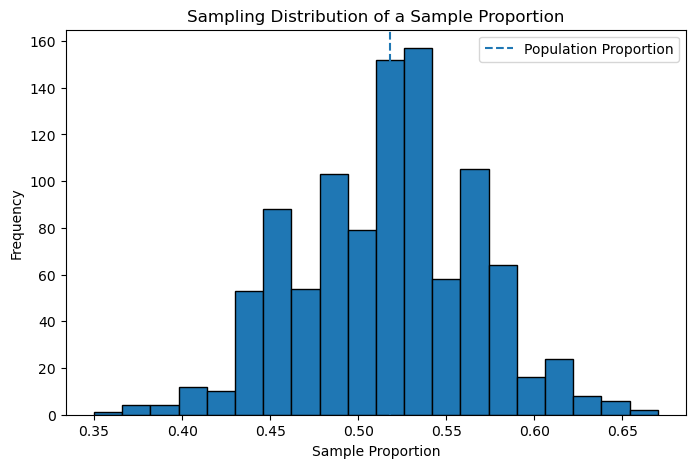

In [25]:
number_of_samples = 1000
sample_size = min(100, len(df))

sample_proportions = []

for seed in range(number_of_samples):
    sample = df.sample(
        n=sample_size,
        replace=True,
        random_state=seed
    )

    proportion = (sample["gender"] == "female").mean()
    sample_proportions.append(proportion)

proportion_distribution = pd.Series(sample_proportions)

print("Population proportion:", population_proportion)
print("Mean of sample proportions:", proportion_distribution.mean())
print(
    "Standard deviation of sample proportions:",
    proportion_distribution.std()
)

plt.figure(figsize=(8, 5))

plt.hist(
    proportion_distribution,
    bins=20,
    edgecolor="black"
)

plt.axvline(
    population_proportion,
    linestyle="--",
    label="Population Proportion"
)

plt.title("Sampling Distribution of a Sample Proportion")
plt.xlabel("Sample Proportion")
plt.ylabel("Frequency")
plt.legend()
plt.show()


#### Interpretation

Each value in the histogram is a sample proportion calculated from one repeated sample.

The distribution shows how the estimated proportion varies across samples.

The mean of the sample proportions should generally be close to the population proportion. The spread describes the variability of the estimates.

As the sample size increases, the sample proportions generally become less variable.

A single sample shows only one possible outcome of the sampling process. Repeated sampling helps us understand how much a statistic can vary across different samples of the same size.

We will:
1. Draw multiple random samples.
2. Calculate the mean math score for each sample.
3. Compare the sample means with the population mean.
4. Observe the variability of the estimates.

This is a useful practical introduction to sampling distributions, which will be covered in the next notebook.


A single sample shows only one possible outcome of the sampling process. Repeated sampling helps us understand how much a statistic can vary across different samples of the same size.

We will:
1. Draw multiple random samples.
2. Calculate the mean math score for each sample.
3. Compare the sample means with the population mean.
4. Observe the variability of the estimates.

This is a useful practical introduction to sampling distributions, which will be covered in the next notebook.

In [9]:
population_mean = df["math score"].mean()

n = min(100, len(df))
number_of_samples = 100

sample_means = []

for seed in range(number_of_samples):
    sample = df.sample(n=n, random_state=seed)
    sample_means.append(sample["math score"].mean())

repeated_sampling = pd.DataFrame({
    "Sample Number": range(1, number_of_samples + 1),
    "Sample Mean": sample_means
})

repeated_sampling["Absolute Error"] = (
    repeated_sampling["Sample Mean"] - population_mean
).abs()

print("Population mean:", population_mean)
print("Mean of sample means:", repeated_sampling["Sample Mean"].mean())
print("Standard deviation of sample means:",
      repeated_sampling["Sample Mean"].std())

repeated_sampling.head()

Population mean: 66.089
Mean of sample means: 66.0393
Standard deviation of sample means: 1.4482537412311074


,Sample Number,Sample Mean,Absolute Error
0,1,65.34,0.749
1,2,64.18,1.909
2,3,66.62,0.531
3,4,66.64,0.551
4,5,65.52,0.569


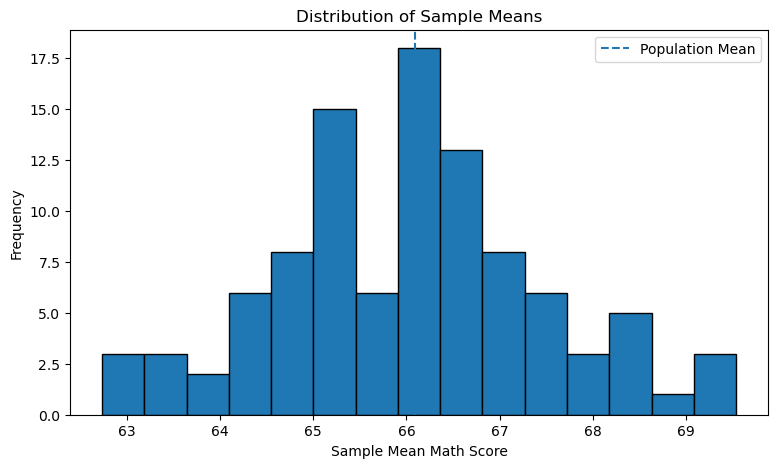

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    repeated_sampling["Sample Mean"],
    bins=15,
    edgecolor="black"
)

plt.axvline(
    population_mean,
    linestyle="--",
    label="Population Mean"
)

plt.title("Distribution of Sample Means")
plt.xlabel("Sample Mean Math Score")
plt.ylabel("Frequency")
plt.legend()
plt.show()

#### Interpretation

Each histogram value represents the mean from one random sample, not an individual student's score.

The sample means will generally vary around the population mean. Their spread shows how much the estimated mean changes across repeated samples.

The standard deviation of these sample means estimates the standard error for this repeated-sampling procedure. This experiment provides the foundation for understanding sampling distributions and the Central Limit Theorem in the next notebook.

### 11. Business Applications

Sampling bias and sample size matter in real business decisions.

#### Customer Satisfaction
If only highly engaged customers answer a survey, the results may not reflect all customers.

#### Product Quality
Inspecting a suitable sample of products can help estimate defect rates without inspecting every item.

#### Marketing Research
A survey that excludes certain customer groups may lead to misleading conclusions about market demand.

#### A/B Testing
The number of participants affects the precision of estimated differences between two versions of a product or campaign.

#### Business Takeaway
Before interpreting a statistic, check how the data was collected, which groups may be missing, and whether the sample size is adequate for the decision.

### 12. Machine Learning Connection


#### 1. Model Evaluation

Accuracy, precision, recall, and other evaluation metrics can vary depending on which observations are included in the test set.

#### 2. Training Data Size

Increasing the training dataset may improve model stability and performance, although improvement is not guaranteed.

#### 3. Class Proportions

The proportion of each class affects the interpretation of classification metrics. Stratified splitting can help preserve class proportions across datasets.

#### 4. Experiment Evaluation

In A/B testing and model comparisons, sampling variability helps us distinguish an observed difference from the uncertainty associated with estimating that difference.

#### 5. Statistical Inference

Sampling distributions and standard errors form the foundation for confidence intervals and many hypothesis tests used in data science.

**Important:** The CLT does not automatically make every model metric normally distributed. The appropriate assumptions and evaluation method depend on the metric and data.

### 13. Key Takeaways

- A sampling distribution describes the distribution of a statistic across repeated samples.
- The sampling distribution of the sample mean describes how sample means vary.
- Standard deviation measures the spread of individual observations.
- Standard error measures the variability of a statistic across repeated samples.
- Under suitable assumptions, the standard error of the mean is the population standard deviation divided by the square root of the sample size.
- Increasing sample size generally reduces standard error.
- The Central Limit Theorem explains why sampling distributions of means often become approximately normal as sample size increases.
- A sample proportion estimates the fraction of a population with a particular characteristic.
- The standard error of a proportion depends on the population proportion and sample size.
- Sampling distributions are important for confidence intervals, hypothesis testing, A/B testing, and model evaluation.

#### Final Thought

A sample statistic is an estimate, not a perfectly certain answer. Sampling distributions help us understand how much that estimate may change from one sample to another.

### Practical Exercises

Use the Student Performance dataset to complete these exercises independently.

#### Exercise 1: Sampling Distribution of the Mean

1. Select 30 students randomly.
2. Calculate the mean math score.
3. Repeat the process 500 times.
4. Plot the resulting sample means.
5. Compare their average with the population mean.

#### Exercise 2: Sample Size and Standard Error

1. Calculate the theoretical standard error for sample sizes 10, 25, 50, and 100.
2. Plot sample size against standard error.
3. Explain why the standard error decreases as sample size increases.

#### Exercise 3: Central Limit Theorem

1. Generate sampling distributions for sample sizes 5, 30, and 100.
2. Compare their shapes.
3. Explain how the sample size affects the distribution of sample means.

#### Exercise 4: Sampling Distribution of a Proportion

1. Calculate the proportion of female students in the full dataset.
2. Draw repeated samples of 50 students.
3. Calculate the proportion in each sample.
4. Plot the distribution of sample proportions.
5. Compare the mean and spread of the sample proportions with the population proportion.

#### Exercise 5: Interpretation

Explain the difference between:

- Standard deviation and standard error
- Sample distribution and sampling distribution
- Sampling distribution of the mean and sampling distribution of a proportion
- Increasing sample size and eliminating sampling bias